## Classification Models

In [41]:
# Import the libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import plot_tree
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
# Load model-ready data from Notebook 03
df = pd.read_csv("../data/processed/model_ready.csv")
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)   # keep both indices in time order

df.info()
print("Rows:", len(df), "| UP days:", round(df["Direction"].mean() * 100, 1), "%")

<class 'pandas.DataFrame'>
RangeIndex: 5844 entries, 0 to 5843
Data columns (total 28 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Date            5844 non-null   datetime64[us]
 1   High_(t-1)      5844 non-null   float64       
 2   Low_(t-1)       5844 non-null   float64       
 3   Close_(t-1)     5844 non-null   float64       
 4   Open_(t-1)      5844 non-null   float64       
 5   Volume_(t-1)    5844 non-null   int64         
 6   SMA_6           5844 non-null   float64       
 7   EMA_26          5844 non-null   float64       
 8   EMA_12          5844 non-null   float64       
 9   MACD            5844 non-null   float64       
 10  MACD_Signal     5844 non-null   float64       
 11  RSI_6           5844 non-null   float64       
 12  RSV_9           5844 non-null   float64       
 13  PSY_13          5844 non-null   float64       
 14  K_9             5844 non-null   float64       
 15  D_3            

### Feature Selection

In [3]:
# From EDA (Objective 4): direction is predicted by MOMENTUM indicators,
# not raw price levels -> keep those 15 features only
x = df[["Prev_Return_%", "Prev_Range_%", "Volatility_30d", "MA_Distance_%", "MACD", "MACD_Signal", "MACD_Hist", "RSI_6", "RSV_9", "PSY_13", "K_9", "D_3", "CMF", "DayOfWeek", "Volume_(t-1)"]]
y = df["Direction"]
print(x.shape, y.shape)

(5844, 15) (5844,)


In [27]:
# Train-Test Split - shuffle=False: learn from the past, test on the newest data
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.15, shuffle=False)
print("Train:", x_train.shape, "| Test:", x_test.shape)

Train: (4967, 15) | Test: (877, 15)


In [28]:
# Feature Scaling
sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

### Logistic Regression

In [36]:
# Model 1 - Logistic Regression
lr = LogisticRegression(max_iter=1000)
lr.fit(x_train, y_train)
y_pred_lr = lr.predict(x_test)
acc_lr = round(accuracy_score(y_test, y_pred_lr) * 100, 1)

print("Logistic Regression  Accuracy:", acc_lr, "%")
print("Confusion Matrix:") 
print(confusion_matrix(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr, target_names=["DOWN", "UP"]))

Logistic Regression  Accuracy: 61.3 %
Confusion Matrix:
[[ 61 282]
 [ 57 477]]
              precision    recall  f1-score   support

        DOWN       0.52      0.18      0.26       343
          UP       0.63      0.89      0.74       534

    accuracy                           0.61       877
   macro avg       0.57      0.54      0.50       877
weighted avg       0.58      0.61      0.55       877



### Gaussian Naive Based

In [37]:
# Model 2 - Naive Bayes
nb = GaussianNB()
nb.fit(x_train, y_train)
y_pred_nb = nb.predict(x_test)
acc_nb = round(accuracy_score(y_test, y_pred_nb) * 100, 1)

print("Naive Bayes  Accuracy:", acc_nb, "%")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_nb))

Naive Bayes  Accuracy: 58.3 %
Confusion Matrix:
[[106 237]
 [129 405]]


### Decision Tree

In [31]:
# Model 3 - Decision Tree
dt = DecisionTreeClassifier(criterion="entropy", random_state=42)
dt.fit(x_train, y_train)
y_pred_dt = dt.predict(x_test)
acc_dt = round(accuracy_score(y_test, y_pred_dt) * 100, 1)

print("Decision Tree  Test Accuracy:", acc_dt, "%")
print("Train Accuracy:", round(accuracy_score(y_train, dt.predict(x_train)) * 100, 1), "%  <- memorised!")
print("Confusion Matrix:"); print(confusion_matrix(y_test, y_pred_dt))

Decision Tree  Test Accuracy: 53.9 %
Train Accuracy: 100.0 %  <- memorised!
Confusion Matrix:
[[170 173]
 [231 303]]


#### Decision Tree Diagram

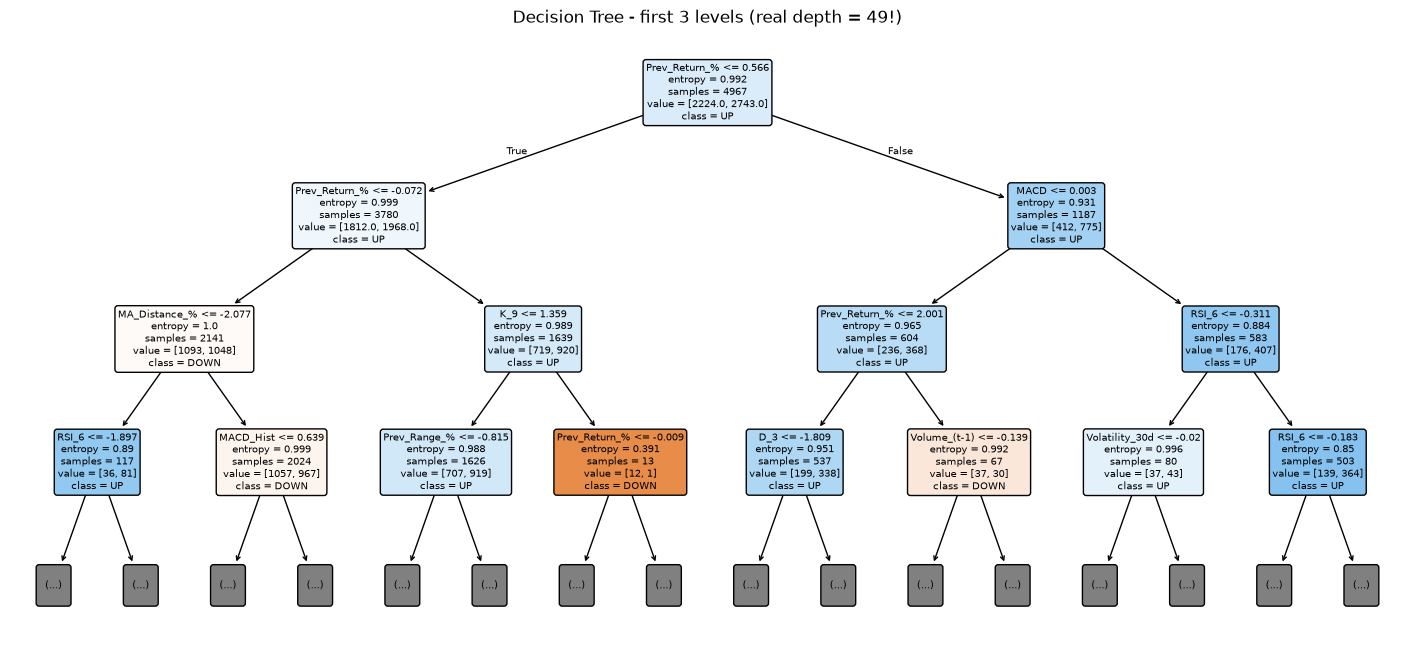

In [39]:
plt.figure(figsize=(18, 8))
plot_tree(dt, filled=True, feature_names=x.columns, class_names=["DOWN", "UP"],
          rounded=True, max_depth=3, fontsize=7)
plt.title("Decision Tree - first 3 levels (real depth = 49!)")
plt.show()

### Random Forest

In [32]:
# Model 4 - Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(x_train, y_train)
y_pred_rf = rf.predict(x_test)
acc_rf = round(accuracy_score(y_test, y_pred_rf) * 100, 1)

print("Random Forest  Accuracy:", acc_rf, "%")
print("Confusion Matrix:"); print(confusion_matrix(y_test, y_pred_rf))

Random Forest  Accuracy: 54.7 %
Confusion Matrix:
[[149 194]
 [203 331]]


#### Random Forest Diagram

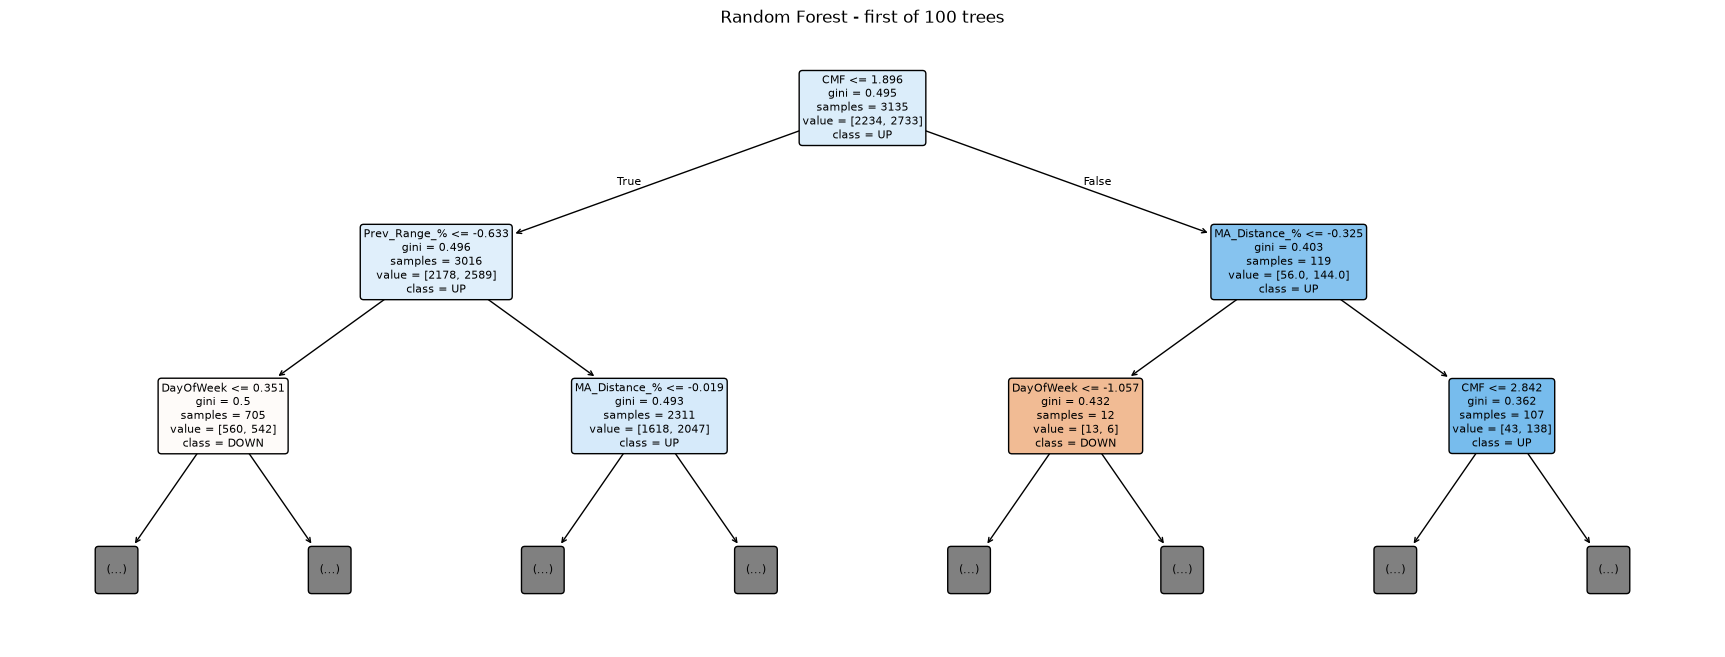

In [40]:
tree = rf.estimators_[0]
plt.figure(figsize=(22, 8))
plot_tree(tree, feature_names=x.columns, class_names=["DOWN", "UP"],
          filled=True, rounded=True, max_depth=2, fontsize=8)
plt.title("Random Forest - first of 100 trees")
plt.show()

### Support Vector Machine

In [33]:
# Model 5 - SVM (linear kernel, like our class file)
svm = SVC(kernel="linear", random_state=42)
svm.fit(x_train, y_train)
y_pred_svm = svm.predict(x_test)
acc_svm = round(accuracy_score(y_test, y_pred_svm) * 100, 1)

print("SVM  Accuracy:", acc_svm, "%")
print("Confusion Matrix:"); print(confusion_matrix(y_test, y_pred_svm))

SVM  Accuracy: 60.9 %
Confusion Matrix:
[[  0 343]
 [  0 534]]


#### SVM Diagram

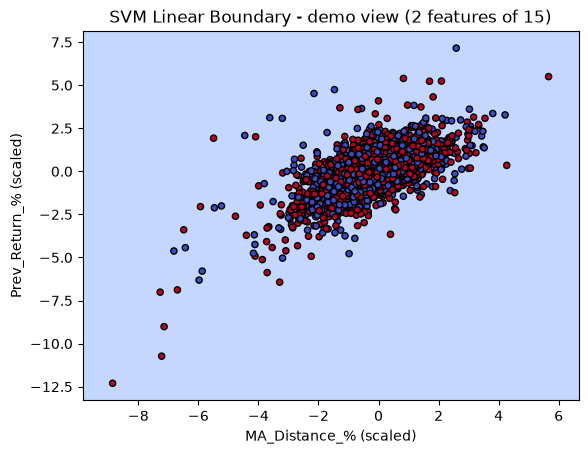

In [43]:
demo = df[["MA_Distance_%", "Prev_Return_%"]]
sc2 = StandardScaler()
demo_sc = sc2.fit_transform(demo)

svm_demo = SVC(kernel="linear", random_state=42)
svm_demo.fit(demo_sc, y)

DecisionBoundaryDisplay.from_estimator(
    svm_demo, demo_sc, response_method="predict",
    cmap="coolwarm", alpha=0.5,
    xlabel="MA_Distance_% (scaled)", ylabel="Prev_Return_% (scaled)")
plt.scatter(demo_sc[:, 0], demo_sc[:, 1], c=y, cmap="coolwarm", edgecolors="k", s=20)
plt.title("SVM Linear Boundary - demo view (2 features of 15)")
plt.show()

### LeaderBoard

In [34]:
# Compare all 5 classifiers
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Naive Bayes", "Decision Tree", "Random Forest", "SVM (linear)"],
    "Accuracy %": [acc_lr, acc_nb, acc_dt, acc_rf, acc_svm]
}).sort_values("Accuracy %", ascending=False).reset_index(drop=True)
print(results)

                 Model  Accuracy %
0  Logistic Regression        61.3
1         SVM (linear)        60.9
2          Naive Bayes        58.3
3        Random Forest        54.7
4        Decision Tree        53.9


## Conclusion - Classification Models (Objective 5)
1. Best-fit model: **Logistic Regression, 61.3% accuracy** - the only model that beat.
2. SVM (linear) matched the baseline (60.9%); Naive Bayes 58.3%; Random Forest 54.7%; Decision Tree 53.9%.
3. Feature selection paid off: the 15 momentum indicators chosen in EDA outperformed all raw columns.
4. Honest finding: daily direction is genuinely hard to predict - a ~1% edge over the naive guess is meaningful in markets.